<a href="https://colab.research.google.com/github/ayanasanthoshkhan/synthetic-clinical-data-generation/blob/main/notebooks/02_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Patient-safe clinical data preprocessing

**Capstone:** Comparative Evaluation of Diffusion, GAN, and VAE Models for Synthetic Clinical Tabular Data Generation: Fidelity, Utility, and Privacy Risk Assessment

**Dataset:** UCI Diabetes 130-US Hospitals (1999–2008), ID 296. **Environment:** Google Colab.

**Objective:** create one consistent set of patient-disjoint real train/test tables for downstream TVAE, CTGAN and TabDDPM experiments. This notebook is **independent of Notebook 01**, so it loads the UCI data again and does not require you to re-run EDA.

### Preprocessing rules agreed after EDA

- Exclude death/hospice discharge codes **11, 13, 14, 19, 20, 21** (confirmed using the dataset `IDs_mapping.csv`), and invalid gender entries.
- Create the **binary** label `readmitted_30` (1 for `<30`; 0 for `>30` or `NO`).
- Keep all eligible encounters, but split by **patient_nbr** (not by row).
- Remove `weight`, `examide`, `citoglipton`; retain clinically relevant missing lab results as **`Not_recorded`**, other categorical missingness as **`Missing`**.
- Convert integer-coded administrative IDs into **categorical strings**; group diagnosis codes to broad ICD-9-CM families (including separate diabetes, `V`, and `E` groups).
- Learn **rare medical-specialty categories and any numerical imputation medians from training rows only**.
- Never include either identifier or the original `readmitted` column in generator training tables.

**Outputs** are written to Google Drive and include two semantic model-input CSVs, a schema/configuration JSON, a patient-split manifest saved **separately**, and a reusable Python module. There is **no TVAE, CTGAN, or TabDDPM training** in this notebook.

Sources: [UCI dataset](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) · [Discharge codebook mirror](https://github.com/opendatasets/UCI.diabetes/blob/master/IDs_mapping.csv).

## 1. Install and import dependencies



In [1]:
%pip install -q ucimlrepo

In [2]:
import json
import sys
import importlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from ucimlrepo import fetch_ucirepo

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
pandas: 2.2.3
scikit-learn: 1.6.1


## 2. Mount Google Drive and create directories



In [3]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/synthetic-clinical-data-generation")
SRC_DIR = PROJECT_ROOT / "src"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results" / "preprocessing"

for folder in (SRC_DIR, PROCESSED_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Processed dataset folder:", PROCESSED_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/synthetic-clinical-data-generation
Processed dataset folder: /content/drive/MyDrive/synthetic-clinical-data-generation/data/processed


## 3. Create the reusable `src/preprocessing.py` module



In [4]:
%%writefile /content/drive/MyDrive/synthetic-clinical-data-generation/src/preprocessing.py
"""Leakage-aware preprocessing for UCI Diabetes 130-US Hospitals (dataset 296).

Only training data determine learned preprocessing choices (rare specialties and
numerical imputation medians). Patient identifiers are used for splitting/audits,
never for model training or synthetic data generation.
"""

from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

DATASET_ID = 296
SEED = 42
TEST_SIZE = 0.20
RARE_SPECIALTY_MIN_COUNT = 100
DEATH_HOSPICE_CODES = (11, 13, 14, 19, 20, 21)
IDENTIFIER_COLS = ("encounter_id", "patient_nbr")
TARGET_SOURCE = "readmitted"
TARGET_BINARY = "readmitted_30"
DROP_COLS = ("weight", "examide", "citoglipton")
DIAG_COLS = ("diag_1", "diag_2", "diag_3")
LAB_COLS = ("A1Cresult", "max_glu_serum")
CODED_CATEGORY_COLS = (
    "admission_type_id", "discharge_disposition_id", "admission_source_id"
)
NUMERIC_FEATURES = (
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses",
)


def assemble_uci_data(features: pd.DataFrame,
                      targets: pd.DataFrame,
                      identifiers: pd.DataFrame) -> pd.DataFrame:
    """Join UCI-provided aligned data tables by their original row order."""
    for name, frame in (("features", features), ("targets", targets),
                        ("identifiers", identifiers)):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError(f"{name} must be a pandas DataFrame")
    n = len(features)
    if len(targets) != n or len(identifiers) != n:
        raise ValueError("UCI features, target and identifiers differ in row count")
    for col in IDENTIFIER_COLS:
        if col not in identifiers.columns:
            raise ValueError(f"Required identifier missing: {col}")
    if TARGET_SOURCE not in targets.columns:
        raise ValueError("Target 'readmitted' missing from targets")
    if features.columns.intersection(targets.columns).size:
        raise ValueError("Overlapping features and target column names")
    if set(features.columns) & set(identifiers.columns):
        raise ValueError("Identifiers were unexpectedly included among features")
    combined = pd.concat(
        [identifiers.reset_index(drop=True), features.reset_index(drop=True),
         targets.reset_index(drop=True)], axis=1
    )
    if combined[list(IDENTIFIER_COLS)].isna().any().any():
        raise ValueError("Missing patient or encounter identifiers")
    if combined["encounter_id"].duplicated().any():
        raise ValueError("Encounter identifiers are not unique")
    return combined


def filter_cohort(data: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Apply prespecified outcome-relevance and invalid-gender exclusions."""
    required = {TARGET_SOURCE, *IDENTIFIER_COLS, "gender", "discharge_disposition_id"}
    missing = required - set(data.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    allowed = {"NO", ">30", "<30"}
    values = set(data[TARGET_SOURCE].dropna().astype(str).unique())
    if data[TARGET_SOURCE].isna().any() or not values.issubset(allowed):
        raise ValueError(f"Unexpected target categories: {values}")

    dispositions = pd.to_numeric(data["discharge_disposition_id"], errors="coerce")
    death_hospice = dispositions.isin(DEATH_HOSPICE_CODES)
    invalid_gender = data["gender"].astype("string").str.strip().str.lower().eq(
        "unknown/invalid"
    ).fillna(False)
    eligible = ~(death_hospice | invalid_gender)
    filtered = data.loc[eligible].copy().reset_index(drop=True)
    filtered[TARGET_BINARY] = filtered[TARGET_SOURCE].eq("<30").astype("int8")

    summary: dict[str, Any] = {
        "original_encounters": int(len(data)),
        "excluded_death_or_hospice": int(death_hospice.sum()),
        "excluded_invalid_gender": int(invalid_gender.sum()),
        "excluded_by_both_rules": int((death_hospice & invalid_gender).sum()),
        "excluded_total_unique_rows": int((~eligible).sum()),
        "remaining_encounters": int(len(filtered)),
        "original_unique_patients": int(data["patient_nbr"].nunique()),
        "remaining_unique_patients": int(filtered["patient_nbr"].nunique()),
        "original_readmitted_30_rate": float(data[TARGET_SOURCE].eq("<30").mean()),
        "remaining_readmitted_30_rate": float(filtered[TARGET_BINARY].mean()),
        "candidate_exclusion_readmission_counts": {
            str(k): int(v) for k, v in
            data.loc[death_hospice, TARGET_SOURCE].value_counts().items()
        },
    }
    return filtered, summary


def grouped_train_test_split(data: pd.DataFrame,
                             test_size: float = TEST_SIZE,
                             seed: int = SEED
                             ) -> tuple[pd.DataFrame, pd.DataFrame]:
    if "patient_nbr" not in data or TARGET_BINARY not in data:
        raise ValueError("patient_nbr and readmitted_30 are required")
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_idx, test_idx = next(
        splitter.split(data, y=data[TARGET_BINARY], groups=data["patient_nbr"])
    )
    train = data.iloc[train_idx].copy().reset_index(drop=True)
    test = data.iloc[test_idx].copy().reset_index(drop=True)
    assert not set(train["patient_nbr"]) & set(test["patient_nbr"]), (
        "Patient leakage detected"
    )
    assert not set(train["encounter_id"]) & set(test["encounter_id"]), (
        "Encounter leakage detected"
    )
    assert len(train) + len(test) == len(data)
    return train, test


def _as_category(series: pd.Series, missing_label: str = "Missing") -> pd.Series:
    result = series.astype("string").str.strip()
    result = result.mask(result.isin(["", "?"]))
    return result.fillna(missing_label).astype(str)


def group_icd9(code: Any) -> str:
    """Map ICD-9-CM diagnosis strings to broad chapters plus diabetes, V, and E."""
    if pd.isna(code):
        return "Missing"
    text = str(code).strip().upper()
    if text in {"", "?", "NAN", "NONE", "MISSING"}:
        return "Missing"
    if re.fullmatch(r"V\d+(?:\.\d+)?", text):
        return "V_Supplementary_factors"
    if re.fullmatch(r"E\d+(?:\.\d+)?", text):
        return "E_External_causes"
    if not re.fullmatch(r"\d{1,3}(?:\.\d+)?", text):
        return "Other_or_unrecognized_code"
    number = int(text.split(".")[0])
    if number == 250:
        return "Diabetes_250"
    chapters = (
        (1, 139, "Infectious_parasitic"),
        (140, 239, "Neoplasms"),
        (240, 279, "Endocrine_nutritional_metabolic"),
        (280, 289, "Blood"),
        (290, 319, "Mental"),
        (320, 389, "Nervous_sense_organs"),
        (390, 459, "Circulatory"),
        (460, 519, "Respiratory"),
        (520, 579, "Digestive"),
        (580, 629, "Genitourinary"),
        (630, 679, "Pregnancy_childbirth"),
        (680, 709, "Skin"),
        (710, 739, "Musculoskeletal"),
        (740, 759, "Congenital"),
        (760, 779, "Perinatal"),
        (780, 799, "Symptoms_ill_defined"),
        (800, 999, "Injury_poisoning"),
    )
    for lower, upper, name in chapters:
        if lower <= number <= upper:
            return name
    return "Other_or_unrecognized_code"


def _clean_semantics(frame: pd.DataFrame) -> pd.DataFrame:
    """Deterministic, row-wise cleaning only; no train/test learned statistics."""
    result = frame.drop(columns=[*IDENTIFIER_COLS, TARGET_SOURCE, *DROP_COLS]).copy()
    for col in DIAG_COLS:
        result[col] = result[col].map(group_icd9).astype(str)
    for col in result.columns:
        if col in NUMERIC_FEATURES or col == TARGET_BINARY:
            continue
        fill = "Not_recorded" if col in LAB_COLS else "Missing"
        result[col] = _as_category(result[col], fill)
    for col in NUMERIC_FEATURES:
        result[col] = pd.to_numeric(result[col], errors="coerce")
    result[TARGET_BINARY] = result[TARGET_BINARY].astype("int8")
    return result


def transform_train_test(train_full: pd.DataFrame, test_full: pd.DataFrame,
                         min_specialty_count: int = RARE_SPECIALTY_MIN_COUNT
                         ) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, Any]]:
    """Prepare semantically typed tables with train-only rare mappings/imputation."""
    train = _clean_semantics(train_full)
    test = _clean_semantics(test_full)

    if list(train.columns) != list(test.columns):
        raise AssertionError("Train/test feature columns differ")

    specialty_counts = train["medical_specialty"].value_counts()
    kept_specialties = sorted([
        str(k) for k, count in specialty_counts.items()
        if count >= min_specialty_count and k != "Missing"
    ])
    for frame in (train, test):
        s = frame["medical_specialty"]
        frame["medical_specialty"] = s.where(
            s.isin(kept_specialties) | s.eq("Missing"), "Other"
        ).astype(str)

    numeric_medians: dict[str, float] = {}
    for col in NUMERIC_FEATURES:
        median = train[col].median()
        if pd.isna(median):
            raise ValueError(f"No observed training values for numeric feature {col}")
        numeric_medians[col] = float(median)
        train[col] = train[col].fillna(median)
        test[col] = test[col].fillna(median)

    for name, frame in (("training", train), ("test", test)):
        if frame.isna().any().any():
            bad = frame.columns[frame.isna().any()].tolist()
            raise AssertionError(f"{name} still has missing values in {bad}")
        if "patient_nbr" in frame or "encounter_id" in frame or TARGET_SOURCE in frame:
            raise AssertionError("Patient/encounter identifiers or original target leaked")
        if not set(frame[TARGET_BINARY].unique()).issubset({0, 1}):
            raise AssertionError("Invalid binary target")

    categorical_features = [
        c for c in train.columns if c not in NUMERIC_FEATURES and c != TARGET_BINARY
    ]
    schema: dict[str, Any] = {
        "dataset_uci_id": DATASET_ID,
        "seed": SEED,
        "split_method": "GroupShuffleSplit(patient_nbr)",
        "test_size_requested_fraction_of_patients": TEST_SIZE,
        "rare_specialty_min_training_count": min_specialty_count,
        "retained_specialties_from_train": kept_specialties,
        "numerical_imputation_medians_from_train": numeric_medians,
        "categorical_feature_columns": categorical_features,
        "numerical_feature_columns": list(NUMERIC_FEATURES),
        "target_column": TARGET_BINARY,
        "target_semantic_type": "categorical_binary",
        "lab_missing_category": "Not_recorded",
        "other_categorical_missing_category": "Missing",
        "removed_columns": list(DROP_COLS),
        "diagnosis_grouping": "ICD-9-CM broad chapters; 250 separated; V/E separate",
        "excluded_discharge_codes": list(DEATH_HOSPICE_CODES),
        "gender_exclusion": "Unknown/Invalid",
    }
    return train, test, schema


def save_outputs(train: pd.DataFrame, test: pd.DataFrame,
                 train_full: pd.DataFrame, test_full: pd.DataFrame,
                 schema: dict[str, Any], cohort_summary: dict[str, Any],
                 output_dir: str | Path) -> dict[str, Path]:
    """Save model-input CSVs + schema and ID-only audit manifest to disk."""
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    train_path = out / "train_semantic.csv"
    test_path = out / "test_semantic.csv"
    train.to_csv(train_path, index=False)
    test.to_csv(test_path, index=False)

    manifest = pd.concat([
        train_full[[*IDENTIFIER_COLS]].assign(split="train"),
        test_full[[*IDENTIFIER_COLS]].assign(split="test"),
    ], ignore_index=True)
    manifest_path = out / "split_manifest_IDS_ONLY.csv"
    manifest.to_csv(manifest_path, index=False)

    summary = {
        **schema,
        "cohort_summary": cohort_summary,
        "train_encounters": len(train),
        "test_encounters": len(test),
        "train_unique_patients": int(train_full["patient_nbr"].nunique()),
        "test_unique_patients": int(test_full["patient_nbr"].nunique()),
        "train_positive_rate": float(train[TARGET_BINARY].mean()),
        "test_positive_rate": float(test[TARGET_BINARY].mean()),
        "training_feature_columns": [c for c in train.columns if c != TARGET_BINARY],
    }
    meta_path = out / "preprocessing_metadata.json"
    with meta_path.open("w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)
    return {"train": train_path, "test": test_path, "manifest": manifest_path,
            "metadata": meta_path}


def load_semantic_csv(path: str | Path, metadata_path: str | Path) -> pd.DataFrame:
    """Reload CSV without losing categorical dtype for integer-coded IDs."""
    with Path(metadata_path).open("r", encoding="utf-8") as f:
        metadata = json.load(f)
    string_columns = metadata["categorical_feature_columns"]
    frame = pd.read_csv(path, dtype={name: "string" for name in string_columns})
    for name in string_columns:
        frame[name] = frame[name].astype(str)
    frame[TARGET_BINARY] = frame[TARGET_BINARY].astype(int)
    return frame

Writing /content/drive/MyDrive/synthetic-clinical-data-generation/src/preprocessing.py


## 4. Load the original UCI data, including identifiers

The UCI loader stores `encounter_id` and `patient_nbr` separately in `data.ids`. We reassemble those tables **in their original row order** and check encounter ID uniqueness. Do not create train/test splits from `features` alone.

In [ ]:
diabetes = fetch_ucirepo(id=296)

X = diabetes.data.features.copy()
y = diabetes.data.targets.copy()
ids = diabetes.data.ids.copy()

print("Features:", X.shape)
print("Target:", y.shape)
print("Identifiers:", ids.shape)

assert "readmitted" in y.columns
assert {"patient_nbr", "encounter_id"}.issubset(ids.columns)

display(ids.head(3))

In [ ]:
sys.path.insert(0, str(SRC_DIR))
import preprocessing
importlib.reload(preprocessing)

from preprocessing import (
    SEED, TEST_SIZE, DEATH_HOSPICE_CODES,
    assemble_uci_data, filter_cohort, grouped_train_test_split,
    transform_train_test, save_outputs, load_semantic_csv,
)

full_data = assemble_uci_data(X, y, ids)

assert full_data["encounter_id"].is_unique
assert len(full_data) == 101766, "Unexpected dataset size; inspect UCI update"

print("Assembled dataset:", full_data.shape)
print("Unique patients:", full_data["patient_nbr"].nunique())
display(full_data[["encounter_id", "patient_nbr", "gender",
                   "discharge_disposition_id", "readmitted"]].head(5))

## 5. Cohort definition and exclusion audit

We apply only **prespecified row-level exclusion rules** here. Code **11** means expired; **13/14** denote hospice; **19/20/21** indicate expired status (Medicaid-specific variants). Some excluded rows have apparently contradictory recorded readmission labels; the dataset is observational and these labels are reported as supplied, not silently corrected.

The EDA found **2,423** candidate discharge-code exclusions in the full 101,766 rows. We print the actual number again rather than assuming a filtered cohort size, because invalid-gender rows may overlap with other exclusions.

In [7]:
excluded_code_mask = pd.to_numeric(
    full_data["discharge_disposition_id"], errors="coerce"
).isin(DEATH_HOSPICE_CODES)

print("Readmission labels in death/hospice-coded encounters:")
display(pd.crosstab(
    full_data.loc[excluded_code_mask, "discharge_disposition_id"],
    full_data.loc[excluded_code_mask, "readmitted"]
))

cohort, cohort_audit = filter_cohort(full_data)

print("\nCohort audit:")
display(pd.DataFrame.from_dict(cohort_audit, orient="index", columns=["Value"]))

assert not pd.to_numeric(
    cohort["discharge_disposition_id"], errors="coerce"
).isin(DEATH_HOSPICE_CODES).any()
assert not cohort["gender"].astype(str).eq("Unknown/Invalid").any()

print("\nRemaining encounters:", len(cohort))

Readmission labels in death/hospice-coded encounters:


readmitted,<30,>30,NO
discharge_disposition_id,,,
11,0,0,1642
13,19,36,344
14,24,7,341
19,0,0,8
20,0,0,2



Cohort audit:


,Value
original_encounters,101766
excluded_death_or_hospice,2423
excluded_invalid_gender,3
excluded_by_both_rules,0
excluded_total_unique_rows,2426
remaining_encounters,99340
original_unique_patients,71518
remaining_unique_patients,69987
original_readmitted_30_rate,0.111599
remaining_readmitted_30_rate,0.113892



Remaining encounters: 99340


## 6. Create a patient-grouped train/test split

An **80/20 split of unique patients** with `GroupShuffleSplit` is used. Because patients have different numbers of encounters, the *row* proportion need not be precisely 80/20. Group splitting is not stratified by the target, so we report class prevalence in both sets.

The held-out real test set must never be used to train the generative models or learn preprocessing statistics.

In [8]:
train_full, test_full = grouped_train_test_split(
    cohort, test_size=TEST_SIZE, seed=SEED
)

train_patients = set(train_full["patient_nbr"])
test_patients = set(test_full["patient_nbr"])

assert len(train_patients.intersection(test_patients)) == 0
assert len(train_full) + len(test_full) == len(cohort)

split_summary = pd.DataFrame({
    "Split": ["Train", "Test", "Total eligible"],
    "Encounters": [len(train_full), len(test_full), len(cohort)],
    "Unique patients": [len(train_patients), len(test_patients),
                        cohort["patient_nbr"].nunique()],
    "Readmitted within 30 days (%)": [
        train_full["readmitted_30"].mean() * 100,
        test_full["readmitted_30"].mean() * 100,
        cohort["readmitted_30"].mean() * 100,
    ],
})

display(split_summary.round(2))
print("Shared patients:", len(train_patients & test_patients))
print("Total encounters represented:", len(train_full) + len(test_full))

,Split,Encounters,Unique patients,Readmitted within 30 days (%)
0,Train,79567,55989,11.40
1,Test,19773,13998,11.35
2,Total eligible,99340,69987,11.39


Shared patients: 0
Total encounters represented: 99340


## 7. Apply semantic cleaning and training-only preprocessing

The helper executes the agreed rules:

- no identifiers or original three-class target in model-input tables;
- missing labs → `Not_recorded`; missing other categories → `Missing`;
- ICD-9 diagnosis codes → documented broad categories, including separate diabetes (`250`), `V`, and `E` groups;
- coded administrative IDs → string categories;
- `medical_specialty` infrequent groups → `Other`, where "infrequent" is defined using **training encounters only** (default: fewer than 100 observations);
- any numerical imputation uses **training medians only**.

This is a shared **semantic representation**, not a one-size-fits-all numerical encoding. TVAE/CTGAN can use categorical metadata; TabDDPM will do its own internal categorical/numeric encoding later, always trained on this same real training split.

In [9]:
train_semantic, test_semantic, schema = transform_train_test(
    train_full, test_full, min_specialty_count=100
)

# Include software versions in the persisted configuration.
from importlib.metadata import version as package_version
schema["software_versions"] = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "ucimlrepo": package_version("ucimlrepo"),
}

print("Training table:", train_semantic.shape)
print("Held-out test table:", test_semantic.shape)
print("Numeric predictors:", len(schema["numerical_feature_columns"]))
print("Categorical predictors:", len(schema["categorical_feature_columns"]))
print("Specialties kept:", len(schema["retained_specialties_from_train"]))

print("\nTraining table preview:")
display(train_semantic.head(3))

print("\nTraining lab missing-value categories:")
for col in ("A1Cresult", "max_glu_serum"):
    print(col, ":", train_semantic[col].value_counts().head(8).to_dict())

Training table: (79567, 45)
Held-out test table: (19773, 45)
Numeric predictors: 8
Categorical predictors: 36
Specialties kept: 25

Training table preview:


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted_30
0,Caucasian,Female,[0-10),6,25,1,1,Missing,Pediatrics-Endocrinology,41,0,1,0,0,0,Diabetes_250,Missing,Missing,1,Not_recorded,Not_recorded,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,0
1,Caucasian,Female,[10-20),1,1,7,3,Missing,Missing,59,0,18,0,0,0,Endocrine_nutritional_metabolic,Diabetes_250,Endocrine_nutritional_metabolic,9,Not_recorded,Not_recorded,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0
2,AfricanAmerican,Female,[20-30),1,1,7,2,Missing,Missing,11,5,13,2,0,1,Pregnancy_childbirth,Diabetes_250,V_Supplementary_factors,6,Not_recorded,Not_recorded,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,0



Training lab missing-value categories:
A1Cresult : {'Not_recorded': 66087, '>8': 6485, 'Norm': 3959, '>7': 3036}
max_glu_serum : {'Not_recorded': 75471, 'Norm': 2050, '>200': 1123, '>300': 923}


## 8. Validate leakage protection, types, and data consistency

These assertions are the **acceptance tests** for the preprocessing milestone. Stop if any assertion fails; do not train models on unvalidated data.

In [10]:
# Column agreement, identifier exclusion, missingness, valid target
assert train_semantic.columns.tolist() == test_semantic.columns.tolist()
assert "readmitted" not in train_semantic.columns
assert "patient_nbr" not in train_semantic.columns
assert "encounter_id" not in train_semantic.columns
assert "weight" not in train_semantic.columns
assert "examide" not in train_semantic.columns
assert "citoglipton" not in train_semantic.columns
assert not train_semantic.isna().any().any()
assert not test_semantic.isna().any().any()
assert set(train_semantic["readmitted_30"].unique()).issubset({0, 1})
assert set(test_semantic["readmitted_30"].unique()).issubset({0, 1})

# Check that categorical codes are *strings*, not continuous floats
for col in ("admission_type_id", "admission_source_id",
            "discharge_disposition_id"):
    assert pd.api.types.is_object_dtype(train_semantic[col])

assert not set(train_full["patient_nbr"]) & set(test_full["patient_nbr"])
assert (train_semantic.columns == test_semantic.columns).all()
assert len(train_semantic) == len(train_full)
assert len(test_semantic) == len(test_full)

# Important: the held-out set is not guaranteed to have identical prevalence.
print("PASS — No patient leakage; consistent columns; no NaNs or identifiers.")
print("Train positive rate:", round(train_semantic["readmitted_30"].mean() * 100, 2), "%")
print("Test positive rate:", round(test_semantic["readmitted_30"].mean() * 100, 2), "%")
print("Absolute positive-rate difference (percentage points):", round(
    abs(train_semantic["readmitted_30"].mean() -
        test_semantic["readmitted_30"].mean()) * 100, 2
))

PASS — No patient leakage; consistent columns; no NaNs or identifiers.
Train positive rate: 11.4 %
Test positive rate: 11.35 %
Absolute positive-rate difference (percentage points): 0.05


## 9. Inspect before/after filtering and splitting

These simple summaries are useful for your methodology report, without repeating the full EDA.

,Dataset,Encounter count,30-day readmission rate (%)
0,Original,101766,11.16
1,Eligible,99340,11.39
2,Train,79567,11.40
3,Test,19773,11.35


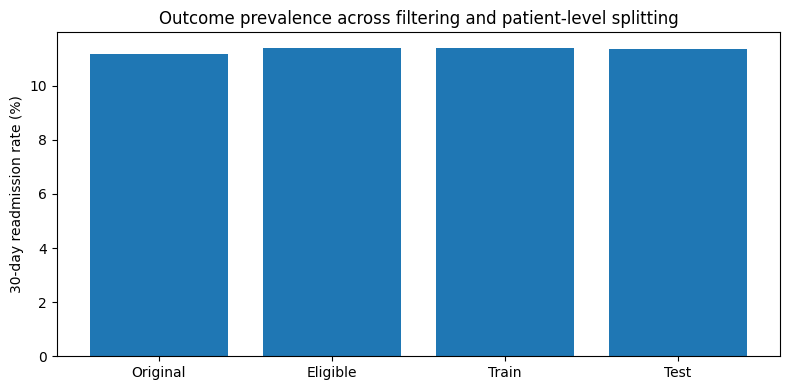

In [11]:
comparison = pd.DataFrame({
    "Dataset": ["Original", "Eligible", "Train", "Test"],
    "Encounter count": [len(full_data), len(cohort), len(train_full), len(test_full)],
    "30-day readmission rate (%)": [
        full_data["readmitted"].eq("<30").mean() * 100,
        cohort["readmitted_30"].mean() * 100,
        train_semantic["readmitted_30"].mean() * 100,
        test_semantic["readmitted_30"].mean() * 100,
    ]
})
display(comparison.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(comparison["Dataset"], comparison["30-day readmission rate (%)"])
ax.set_ylabel("30-day readmission rate (%)")
ax.set_title("Outcome prevalence across filtering and patient-level splitting")
plt.tight_layout()
plt.show()

## 10. Save model-ready datasets, split manifest, and metadata to Drive

- `train_semantic.csv`: **real train** (all eligible encounters belonging to train patients)
- `test_semantic.csv`: **held-out real test** (must not be passed to a generator's `.fit()`)
- `preprocessing_metadata.json`: categorical/numeric schema, target meaning, learned category mapping, numeric train medians, filtering counts, seeds, split information
- `split_manifest_IDS_ONLY.csv`: **audit only** — contains encounter and patient IDs with train/test labels. Never pass this manifest to any generator or classifier.

**CSV caution:** Pandas automatically guesses dtypes. To prevent integer-coded categories being misread as numbers in later notebooks, use `load_semantic_csv` with the JSON metadata.

In [12]:
saved_paths = save_outputs(
    train_semantic, test_semantic,
    train_full, test_full,
    schema, cohort_audit,
    PROCESSED_DIR,
)

print("Saved files:")
for label, path in saved_paths.items():
    print(f"{label:>10}: {path} ({path.stat().st_size:,} bytes)")

# Keep a small report-ready table with this notebook.
split_summary.to_csv(RESULTS_DIR / "split_summary.csv", index=False)
comparison.to_csv(RESULTS_DIR / "cohort_comparison.csv", index=False)
print("\nReport summaries:", RESULTS_DIR)

Saved files:
     train: /content/drive/MyDrive/synthetic-clinical-data-generation/data/processed/train_semantic.csv (16,655,754 bytes)
      test: /content/drive/MyDrive/synthetic-clinical-data-generation/data/processed/test_semantic.csv (4,141,232 bytes)
  manifest: /content/drive/MyDrive/synthetic-clinical-data-generation/data/processed/split_manifest_IDS_ONLY.csv (2,423,971 bytes)
  metadata: /content/drive/MyDrive/synthetic-clinical-data-generation/data/processed/preprocessing_metadata.json (4,411 bytes)

Report summaries: /content/drive/MyDrive/synthetic-clinical-data-generation/results/preprocessing


## 11. Reload from disk and verify the files actually work

This guards against lost categorical types when reading CSV. **Later notebooks should use this same loader.**

In [13]:
train_reload = load_semantic_csv(
    saved_paths["train"], saved_paths["metadata"]
)
test_reload = load_semantic_csv(
    saved_paths["test"], saved_paths["metadata"]
)

with open(saved_paths["metadata"], "r", encoding="utf-8") as f:
    saved_metadata = json.load(f)

assert train_reload.shape == train_semantic.shape
assert test_reload.shape == test_semantic.shape
assert train_reload.columns.tolist() == train_semantic.columns.tolist()
assert test_reload.columns.tolist() == test_semantic.columns.tolist()
assert pd.api.types.is_object_dtype(train_reload["admission_type_id"])
assert not train_reload.isna().any().any()
assert not test_reload.isna().any().any()
assert saved_metadata["train_encounters"] == len(train_semantic)
assert saved_metadata["test_encounters"] == len(test_semantic)

manifest_reload = pd.read_csv(saved_paths["manifest"])
pid_train = set(manifest_reload.loc[
    manifest_reload["split"] == "train", "patient_nbr"
])
pid_test = set(manifest_reload.loc[
    manifest_reload["split"] == "test", "patient_nbr"
])
assert not pid_train & pid_test

print("PASS — Stored CSVs, schema, and split manifest reloaded successfully.")
print("Files are saved persistently in your Google Drive project folder.")

PASS — Stored CSVs, schema, and split manifest reloaded successfully.
Files are saved persistently in your Google Drive project folder.


## Preprocessing — Final Summary

The preprocessing pipeline was successfully executed and validated on the UCI Diabetes 130-US Hospitals dataset.

### Results

- **Original dataset:** 101,766 hospital encounters.
- **Final eligible cohort:** 99,340 encounters after excluding 2,423 death/hospice discharges and 3 invalid-gender records.
- **Training dataset:** 79,567 encounters.
- **Held-out test dataset:** 19,773 encounters.
- **Patient overlap:** 0 shared patients between training and testing.
- **Training 30-day readmission prevalence:** 11.40%.
- **Test 30-day readmission prevalence:** 11.35%.
- **Final feature schema:** 8 numerical predictors, 36 categorical predictors and 1 binary target.

### Validation

All preprocessing validation checks passed. The processed datasets contain no missing values or patient identifiers, and the saved files were successfully reloaded using the metadata-aware loader.

Data-dependent preprocessing was fitted using training data only. The real test dataset remains held out for downstream evaluation.

### Next Stage

Train a real-data classification baseline, followed by TVAE and CTGAN using the processed training dataset. The `readmitted_30` target will be treated as categorical during synthetic data generation.